In [1]:
import sys
import os

In [2]:
project_root = os.path.abspath(os.path.join(os.getcwd(), "..", "..", ".."))

if project_root not in sys.path:
    sys.path.append(project_root)

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
        
from core.models import GetModel
import json

In [4]:
def GetModelFromConfig(path):
    config_path =  "config.json"
    with open(config_path, "r") as f:
        config = json.load(f)
                
    model = GetModel(config)
    
    return model, config["experiment"]["N"]

In [5]:
import plotly.graph_objects as go
from sklearn.decomposition import PCA
import numpy as np

def plot_input_only_plotly(model, N):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    offset = 2 * N * N 
    labels = np.arange(-N, N + 1)
    indices = labels + offset
    
    valid_indices = [i for i in indices if 0 <= i < weights.shape[0]]
    input_weights = weights[valid_indices]
    labels = labels[:len(valid_indices)]
    
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(input_weights)
    

    fig = go.Figure()
    
    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top center",
        marker=dict(
            size=14,
            color='red',
            line=dict(width=1, color='black')
        ),
        hoverinfo='text',
        hovertext=[f"Wartość wejściowa: {l}<br>Index w embed: {l + offset}" for l in labels]
    ))
    
    fig.update_layout(
        title=f"Struktura liczb wejściowych (Embeddings) dla N={N}",
        xaxis_title="PCA Component 1",
        yaxis_title="PCA Component 2",
        plot_bgcolor='white',
        width=700,
        height=700
    )
    
    fig.update_xaxes(showgrid=True, gridcolor='lightgray')
    fig.update_yaxes(showgrid=True, gridcolor='lightgray')
    
    fig.show()

In [6]:
model, N = GetModelFromConfig("")

model_path = r"checkpoint_epoch_20000.pt"

checkpoint = torch.load(model_path, map_location="cpu")

model_weights = checkpoint["model_state_dict"]
model.load_state_dict(model_weights)

plot_input_only_plotly(model, N=N)

In [7]:
import torch
import pandas as pd
import plotly.express as px
from sklearn.decomposition import PCA

def plot_embeddings_3d(model, title="Osadzenia Wejściowe 3D"):
    # 1. Wyciągamy wagi embeddingów (zakładam nazwę warstwy embedding w modelu)
    # Jeśli Twoja warstwa nazywa się inaczej, np. model.tok_emb.weight, popraw to poniżej:
    embeddings = model.tokens_embed.weight.detach().cpu().numpy()
    
    # 2. Liczymy PCA dla 3 komponentów
    pca = PCA(n_components=3)
    embeddings_3d = pca.fit_transform(embeddings)
    
    # Tworzymy listę etykiet (indeksów liczb, np. od -50 do 50, w zależności od Twojego słownika)
    # Zakładam, że indeksy odpowiadają kolejnym tokenom w embeddingu
    num_tokens = embeddings.shape[0]
    labels = [str(i - num_tokens//2) for i in range(num_tokens)] # Przykładowe centrowanie wokół zera
    
    # Wartości do pokolorowania punktów (np. moduł liczby, żeby zobaczyć gradient)
    values = [abs(i - num_tokens//2) for i in range(num_tokens)]
    
    # 3. Pakujemy dane do DataFrame dla Plotly
    df = pd.DataFrame({
        'PCA 1': embeddings_3d[:, 0],
        'PCA 2': embeddings_3d[:, 1],
        'PCA 3': embeddings_3d[:, 2],
        'Token': labels,
        'Wartość': values
    })
    
    # 4. Generujemy interaktywny wykres 3D
    fig = px.scatter_3d(
        df, 
        x='PCA 1', 
        y='PCA 2', 
        z='PCA 3',
        text='Token',
        color='Wartość',
        color_continuous_scale='Viridis',
        title=title
    )
    
    # Dostosowanie wyglądu punktów i tekstu
    fig.update_traces(
        marker=dict(size=5, line=dict(width=1, color='DarkSlateGrey')),
        textposition='top center'
    )
    
    fig.show()

# Wywołanie (podstaw swój wytrenowany model):
plot_embeddings_3d(model)

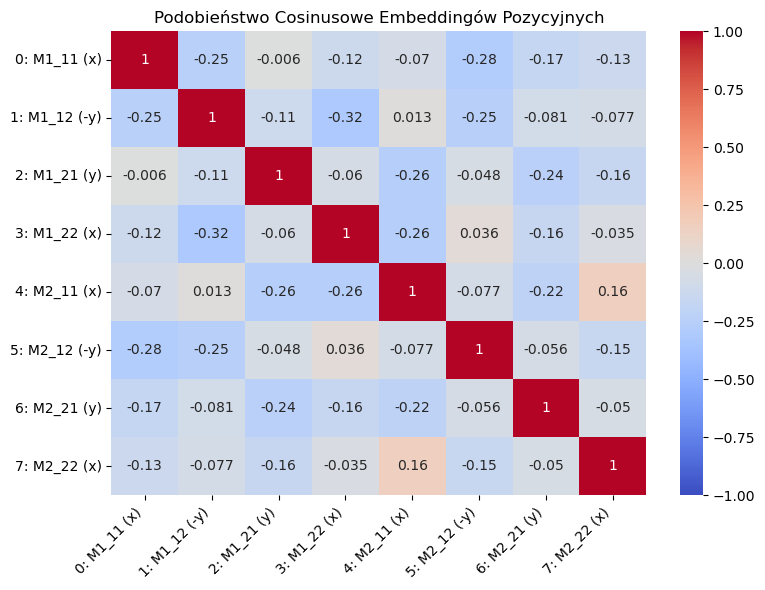

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_positional_embeddings(model):
    pos_weights = model.pos_embed.weight.detach().cpu().numpy()
    
    norm = np.linalg.norm(pos_weights, axis=1, keepdims=True)
    normalized_pos = pos_weights / norm
    
    cosine_sim = np.dot(normalized_pos, normalized_pos.T)
    
    plt.figure(figsize=(8, 6))
    

    labels = [
        '0: M1_11 (x)', '1: M1_12 (-y)', '2: M1_21 (y)', '3: M1_22 (x)',
        '4: M2_11 (x)', '5: M2_12 (-y)', '6: M2_21 (y)', '7: M2_22 (x)'
    ]
    
    sns.heatmap(
        cosine_sim, 
        annot=True, 
        cmap="coolwarm", 
        xticklabels=labels, 
        yticklabels=labels,
        vmin=-1, vmax=1
    )
    
    plt.title("Podobieństwo Cosinusowe Embeddingów Pozycyjnych")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


analyze_positional_embeddings(model)

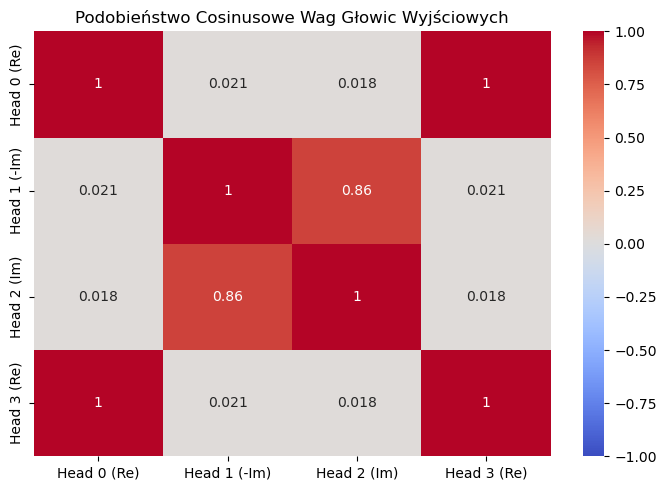

In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_output_heads(model):
    heads_weights = [head.weight.detach().cpu().numpy() for head in model.output_heads]
    
    flat_heads = [w.flatten() for w in heads_weights]
    flat_heads = np.array(flat_heads) 
    
    norm = np.linalg.norm(flat_heads, axis=1, keepdims=True)
    normalized_heads = flat_heads / norm
    head_sim = np.dot(normalized_heads, normalized_heads.T)
    
    labels = ['Head 0 (Re)', 'Head 1 (-Im)', 'Head 2 (Im)', 'Head 3 (Re)']
    
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        head_sim, 
        annot=True, 
        cmap="coolwarm", 
        xticklabels=labels, 
        yticklabels=labels,
        vmin=-1, vmax=1
    )
    plt.title("Podobieństwo Cosinusowe Wag Głowic Wyjściowych")
    plt.tight_layout()
    plt.show()

analyze_output_heads(model)

In [10]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly(model, N, head_idx=0):
    """
    Rysuje interaktywny wykres 2D PCA dla wybranej głowicy wyjściowej.
    head_idx: 0 -> Re (górna lewa), 1 -> -Im (górna prawa), 2 -> Im (dolna lewa), 3 -> Re (dolna prawa)
    """
    # Wyciągamy wagi konkretnej głowicy z nn.ModuleList
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Nasz zsynchronizowany offset w nowym datasiecie
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []

    print(weights.shape[0])
    
    for val in range(min_val, max_val + 1):
        idx = val
        if min_val <= idx < max_val:
            active_indices.append(idx + output_offset)
            labels.append(val)

    active_weights = weights[active_indices]

    # Twój filtr normy, usuwający słabo aktywne tokeny krańcowe
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.0
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Redukcja wymiarowości wag do 2D
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    
    # Mapowanie nazw głowic do tytułu wykresu
    head_names = {0: "Re (Head 0)", 1: "-Im (Head 1)", 2: "Im (Head 2)", 3: "Re (Head 3)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=10, family="Arial Black"),
        marker=dict(
            size=12,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura wyjść dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        xaxis=dict(title="PCA Component 1", gridcolor='rgba(200,200,200,0.2)'),
        yaxis=dict(title="PCA Component 2", gridcolor='rgba(200,200,200,0.2)'),
        plot_bgcolor='white',
        paper_bgcolor='white',
        width=900,
        height=800,
        showlegend=False
    )
    
    fig.show()

In [11]:
# Wizualizacja pierwszej głowicy rzeczywistej (Head 0)
plot_output_head_plotly(model, N=N, head_idx=0)

plot_output_head_plotly(model, N=N, head_idx=1)

# Wizualizacja głowicy urojonej (Head 2)
plot_output_head_plotly(model, N=N, head_idx=2)

plot_output_head_plotly(model, N=N, head_idx=3)


197


197


197


197


In [12]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly_3d(model, N, head_idx=0):
    """
    Rysuje interaktywny wykres 3D PCA dla wybranej głowicy wyjściowej.
    head_idx: 0 -> Re, 1 -> -Im, 2 -> Im, 3 -> Re
    """
    # Wyciągamy wagi konkretnej głowicy
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Zsynchronizowany offset
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if min_val <= val < max_val:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    # Filtr aktywności tokenów krańcowych
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Redukcja wymiarowości wag do 3D
    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    
    # Mapowanie nazw głowic
    head_names = {0: "Re (Head 0)", 1: "-Im (Head 1)", 2: "Im (Head 2)", 3: "Re (Head 3)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D wyjść dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="PCA 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="PCA 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="PCA 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

In [13]:
plot_output_head_plotly_3d(model, N=N, head_idx=0)

plot_output_head_plotly_3d(model, N=N, head_idx=2)

In [14]:
import numpy as np
import plotly.graph_objects as go
from sklearn.manifold import TSNE

def plot_output_head_tsne(model, N, head_idx=0, perplexity=10, random_state=13):
    """
    Rysuje interaktywny wykres 2D t-SNE dla wybranej głowicy wyjściowej.
    head_idx: 0 -> Re (górna lewa), 1 -> -Im (górna prawa), 2 -> Im (dolna lewa), 3 -> Re (dolna prawa)
    """
    # Wyciągamy wagi konkretnej głowicy z nn.ModuleList (dokładnie jak w Twoim szablonie)
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Nasz zsynchronizowany offset w nowym datasiecie
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    # Twój filtr normy, usuwający słabo aktywne tokeny krańcowe
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.0
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Bezpiecznik dla perplexity: t-SNE wymaga, aby perplexity < liczba próbek
    n_samples = active_weights.shape[0]
    actual_perplexity = min(perplexity, max(1, n_samples - 1))

    # Redukcja wymiarowości wag do 2D za pomocą t-SNE (bez parametru n_iter)
    tsne = TSNE(
        n_components=2, 
        perplexity=actual_perplexity, 
        random_state=random_state
    )
    embeds_2d = tsne.fit_transform(active_weights)
    
    # Mapowanie nazw głowic do tytułu wykresu
    head_names = {0: "Re (Head 0)", 1: "-Im (Head 1)", 2: "Im (Head 2)", 3: "Re (Head 3)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=10, family="Arial Black"),
        marker=dict(
            size=12,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura wyjść t-SNE dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        xaxis=dict(title="t-SNE Dimension 1", gridcolor='rgba(200,200,200,0.2)'),
        yaxis=dict(title="t-SNE Dimension 2", gridcolor='rgba(200,200,200,0.2)'),
        plot_bgcolor='white',
        paper_bgcolor='white',
        width=900,
        height=800,
        showlegend=False
    )
    
    fig.show()

plot_output_head_tsne(model, N=N)
plot_output_head_tsne(model, N=N,head_idx=1)

In [15]:
import numpy as np
import plotly.graph_objects as go
from sklearn.manifold import TSNE

def plot_output_head_tsne_3d(model, N, head_idx=0, perplexity=30, random_state=42):
    """
    Rysuje interaktywny wykres 3D t-SNE dla wybranej głowicy wyjściowej.
    head_idx: 0 -> Re (górna lewa), 1 -> -Im (górna prawa), 2 -> Im (dolna lewa), 3 -> Re (dolna prawa)
    """
    # Wyciągamy wagi konkretnej głowicy z nn.ModuleList (dokładnie jak w Twoim szablonie)
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Nasz zsynchronizowany offset w datasiecie
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    # Twój filtr normy, usuwający słabo aktywne tokeny krańcowe
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.0
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Bezpiecznik dla perplexity: t-SNE wymaga, aby perplexity < liczba próbek
    n_samples = active_weights.shape[0]
    actual_perplexity = min(perplexity, max(1, n_samples - 1))

    # Redukcja wymiarowości wag do 3D za pomocą t-SNE
    tsne = TSNE(
        n_components=3, 
        perplexity=actual_perplexity, 
        random_state=random_state
    )
    embeds_3d = tsne.fit_transform(active_weights)
    
    # Mapowanie nazw głowic do tytułu wykresu
    head_names = {0: "Re (Head 0)", 1: "-Im (Head 1)", 2: "Im (Head 2)", 3: "Re (Head 3)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    # Używamy Scatter3d zamiast Scatter
    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6, # W 3D mniejszy marker wygląda czytelniej przy obracaniu
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura wyjść 3D t-SNE dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="t-SNE Dim 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="t-SNE Dim 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="t-SNE Dim 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            bgcolor='white'
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

plot_output_head_tsne_3d(model, N=N)

In [16]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

def analyze_pca_clusters(model, N, head_idx=3, shift=81):
    """
    Automatycznie dzieli wykres PCA na 3 kolumny i wylicza statystyki 
    teorii liczb dla każdej z nich, sprawdzając co model tam zakodował.
    """
    # 1. Wyciągamy wagi i filtrujemy dokładnie tak jak do wykresu
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.0
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # 2. Liczymy PCA 2D
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    
    # 3. Automatyczny podział na 3 klastry wzdłuż osi X (składnik PCA 1)
    # Używamy KMeans, żeby komputer sam idealnie odseparował te 3 pionowe kolumny
    x_coords = embeds_2d[:, 0].reshape(-1, 1)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(x_coords)
    cluster_ids = kmeans.labels_
    
    # Tworzymy DataFrame do łatwej analizy statystycznej
    df = pd.DataFrame({
        'val': labels,
        'x': embeds_2d[:, 0],
        'y': embeds_2d[:, 1],
        'cluster': cluster_ids
    })
    
    # Porządkujemy klastry od lewej do prawej na podstawie średniej współrzędnej X
    cluster_mapping = df.groupby('cluster')['x'].mean().sort_values().index
    cluster_names = {cluster_mapping[0]: 'Lewa Kolumna', cluster_mapping[1]: 'Środkowa Kolumna', cluster_mapping[2]: 'Prawa Kolumna'}
    df['cluster_name'] = df['cluster'].map(cluster_names)
    
    # 4. Definiujemy cechy matematyczne do przetestowania
    def get_math_properties(v):
        return {
            'Dodatnia': v > 0,
            'Ujemna': v < 0,
            'Zero': v == 0,
            'Parzysta': v % 2 == 0 and v != 0,
            'Podzielna przez 3': v % 3 == 0 and v != 0,
            'Podzielna przez 5': v % 5 == 0 and v != 0,
            'Podzielna przez 7': v % 7 == 0 and v != 0,
            'Jest kwadratem': int(np.sqrt(abs(v)))**2 == abs(v) and v != 0
        }

    # 5. Analiza statystyczna każdego klastra
    # 5. Analiza statystyczna każdego klastra
    print(f"=== RAPORT ANALIZY KLASTRÓW DLA GŁOWICY {head_idx} ===")
    for name in ['Lewa Kolumna', 'Środkowa Kolumna', 'Prawa Kolumna']:
        sub_df = df[df['cluster_name'] == name]
        total_in_cluster = len(sub_df)
        
        if total_in_cluster == 0:
            print(f"\n{name.upper()} jest pusty.")
            continue
            
        # Bezpieczne próbkowanie: wyciągamy do 10 losowych przykładów z kolumny
        sample_size = min(10, total_in_cluster)
        samples = sub_df['val'].sample(n=sample_size, random_state=42).tolist()
        
        print(f"\n{name.upper()} (Liczba tokenów: {total_in_cluster})")
        print(f"Przykładowe liczby w tej kolumnie: {samples}")
        print(f"Zakres wartości: od {sub_df['val'].min()} do {sub_df['val'].max()}")
        
        prop_counts = {k: 0 for k in get_math_properties(1).keys()}
        for val in sub_df['val']:
            props = get_math_properties(val)
            for k, v in props.items():
                if v: prop_counts[k] += 1
                
        print("Profil matematyczny kolumny:")
        for prop, count in prop_counts.items():
            percentage = (count / total_in_cluster) * 100
            # Obniżono próg do 10%, żeby nie przegapić słabszych, ale ważnych sygnałów strukturalnych
            if percentage > 10: 
                print(f"  - {prop}: {percentage:.1f}% ({count} szt.)")
                
    print("="*50)

# Uruchomienie (podstaw pod 'model' swój obiekt sieci)
analyze_pca_clusters(model, N=9, head_idx=0)

=== RAPORT ANALIZY KLASTRÓW DLA GŁOWICY 0 ===

LEWA KOLUMNA (Liczba tokenów: 78)
Przykładowe liczby w tej kolumnie: [-109, -162, -108, -130, -133, -65, -112, -142, -93, -76]
Zakres wartości: od -162 do -65
Profil matematyczny kolumny:
  - Ujemna: 100.0% (78 szt.)
  - Parzysta: 50.0% (39 szt.)
  - Podzielna przez 3: 33.3% (26 szt.)
  - Podzielna przez 5: 20.5% (16 szt.)
  - Podzielna przez 7: 12.8% (10 szt.)

ŚRODKOWA KOLUMNA (Liczba tokenów: 41)
Przykładowe liczby w tej kolumnie: [12, -146, -152, 16, -157, 33, -132, 32, 21, -154]
Zakres wartości: od -161 do 33
Profil matematyczny kolumny:
  - Dodatnia: 48.8% (20 szt.)
  - Ujemna: 51.2% (21 szt.)
  - Parzysta: 51.2% (21 szt.)
  - Podzielna przez 3: 31.7% (13 szt.)
  - Podzielna przez 5: 14.6% (6 szt.)
  - Podzielna przez 7: 17.1% (7 szt.)
  - Jest kwadratem: 12.2% (5 szt.)

PRAWA KOLUMNA (Liczba tokenów: 78)
Przykładowe liczby w tej kolumnie: [-30, -63, -29, -51, -53, 34, -33, -59, -14, 3]
Zakres wartości: od -63 do 34
Profil matematycz

In [17]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly_mod(model, N, mod, head_idx=0):
    """
    Rysuje interaktywny wykres 2D PCA dla wybranej głowicy wyjściowej z podziałem na mod 5.
    Liczby podzielne przez 5 są czerwone, reszta niebieska.
    """
    # Wyciągamy wagi konkretnej głowicy z nn.ModuleList
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Nasz zsynchronizowany offset w nowym datasiecie
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []

    print(weights.shape[0])
    
    for val in range(min_val, max_val + 1):
        idx = val
        if min_val <= idx < max_val:
            active_indices.append(idx + output_offset)
            labels.append(val)

    active_weights = weights[active_indices]

    # Twój filtr normy, usuwający słabo aktywne tokeny krańcowe
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.0
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Redukcja wymiarowości wag do 2D
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    
    # Mapowanie kolorów: 1 dla podzielnych przez 5 (oprócz 0), 0 dla reszty
    # Jeśli chcesz wliczać zero, usuń warunek: and l != 0
    color_values = [1 if (l % mod == 0 and l != 0) else 0 for l in labels]
    
    # Definiujemy prostą, sztywną mapę: 0 -> niebieski, 1 -> czerwony
    custom_colorscale = [
        [0.0, 'rgb(31, 119, 180)'],  # Czysty niebieski
        [1.0, 'rgb(214, 39, 40)']    # Czysty czerwony
    ]

    # Mapowanie nazw głowic do tytułu wykresu
    head_names = {0: "Re (Head 0)", 1: "-Im (Head 1)", 2: "Im (Head 2)", 3: "Re (Head 3)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=10, family="Arial Black"),
        marker=dict(
            size=12,
            color=color_values,
            colorscale=custom_colorscale,
            showscale=True,
            colorbar=dict(
                title="Podzielność przez 5",
                tickmode='array',
                tickvals=[0, 1],
                ticktext=['Inne (Niebieskie)', 'Mod 5 (Czerwone)']
            ),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}<br>Reszta mod 5: {l % 5}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Struktura wyjść (Podział Mod 5) dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        xaxis=dict(title="PCA Component 1", gridcolor='rgba(200,200,200,0.2)'),
        yaxis=dict(title="PCA Component 2", gridcolor='rgba(200,200,200,0.2)'),
        plot_bgcolor='white',
        paper_bgcolor='white',
        width=900,
        height=800,
        showlegend=False
    )
    
    fig.show()

plot_output_head_plotly_mod(model, N=N, mod=5)
plot_output_head_plotly_mod(model, N=N, mod=7)

197


197


In [18]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly_universal_mod(model, N, head_idx=0, mod_base=5):
    """
    Rysuje wykres 2D PCA i podświetla liczby podzielne przez podaną podstawę (mod_base).
    """
    # Wyciągamy wagi konkretnej głowicy z nn.ModuleList
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Nasz zsynchronizowany offset w nowym datasiecie
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val
        if min_val <= idx < max_val:
            active_indices.append(idx + output_offset)
            labels.append(val)

    active_weights = weights[active_indices]

    # Twój filtr normy
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.0
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Redukcja wymiarowości wag do 2D
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    
    # Dynamiczne mapowanie kolorów dla wybranej bazy modulo
    color_values = [1 if (l % mod_base == 0 and l != 0) else 0 for l in labels]
    
    custom_colorscale = [
        [0.0, 'rgb(31, 119, 180)'],  # Niebieski (reszta)
        [1.0, 'rgb(214, 39, 40)']    # Czerwony (podzielne przez mod_base)
    ]

    head_names = {0: "Re (Head 0)", 1: "-Im (Head 1)", 2: "Im (Head 2)", 3: "Re (Head 3)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=10, family="Arial Black"),
        marker=dict(
            size=12,
            color=color_values,
            colorscale=custom_colorscale,
            showscale=True,
            colorbar=dict(
                title=f"Podzielność przez {mod_base}",
                tickmode='array',
                tickvals=[0, 1],
                ticktext=['Inne', f'Mod {mod_base}']
            ),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość: {l}<br>Reszta mod {mod_base}: {l % mod_base}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Struktura wyjść (Podział Mod {mod_base}) dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        xaxis=dict(title="PCA Component 1", gridcolor='rgba(200,200,200,0.2)'),
        yaxis=dict(title="PCA Component 2", gridcolor='rgba(200,200,200,0.2)'),
        plot_bgcolor='white',
        paper_bgcolor='white',
        width=900,
        height=800,
        showlegend=False
    )
    
    fig.show()

plot_output_head_plotly_universal_mod(model, N=N, head_idx=3, mod_base=5)

In [19]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly_3d_mod5(model, N, head_idx=0):
    """
    Rysuje interaktywny wykres 3D PCA dla wybranej głowicy wyjściowej.
    Liczby podzielne przez 5 są czerwone, reszta niebieska.
    """
    # Wyciągamy wagi konkretnej głowicy
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    # Zsynchronizowany offset
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    # Filtr aktywności tokenów krańcowe (zgodnie z Twoim nowym progiem 0.4)
    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    # Redukcja wymiarowości wag do 3D za pomocą PCA
    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    
    # Tworzymy binarną tablicę kolorów dla mod 5 (z pominięciem zera)
    color_values = [1 if (l % 5 == 3 or l % 5 == 2 ) else 0 for l in labels]
    
    # Czyste, kontrastowe odcień: 0 -> Niebieski, 1 -> Czerwony
    custom_colorscale = [
        [0.0, 'rgb(31, 119, 180)'],
        [1.0, 'rgb(214, 39, 40)']
    ]
    
    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=color_values,
            colorscale=custom_colorscale,
            showscale=True,
            colorbar=dict(
                title="Podzielność przez 5",
                tickmode='array',
                tickvals=[0, 1],
                ticktext=['Inne (Niebieskie)', 'Mod 5 (Czerwone)']
            ),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}<br>Reszta mod 5: {l % 5}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D (Podział Mod 5) dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="PCA 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="PCA 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="PCA 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

plot_output_head_plotly_3d_mod5(model, N=N, head_idx=0)
plot_output_head_plotly_3d_mod5(model, N=N, head_idx=1)